In [1]:
# Check: is Ollama already running on this machine?
!ollama list

/bin/bash: line 1: ollama: command not found


# Tutorial 02: tools and the agent loop

**Part A: Setup.** Run these cells first in every new Colab session.

In [2]:
# Cell 1: Confirm Colab gave us a GPU
!nvidia-smi --query-gpu=name,memory.total --format=csv

name, memory.total [MiB]
Tesla T4, 15360 MiB


In [3]:
# Cell 2: Install zstd (unpacking) and pciutils + lshw (GPU detection)
!apt-get install -y -q zstd pciutils lshw

Reading package lists...
Building dependency tree...
Reading state information...
The following additional packages will be installed:
  libpci3 pci.ids usb.ids
The following NEW packages will be installed:
  libpci3 lshw pci.ids pciutils usb.ids zstd
0 upgraded, 6 newly installed, 0 to remove and 33 not upgraded.
Need to get 1,583 kB of archives.
After this operation, 5,343 kB of additional disk space will be used.
Get:1 http://archive.ubuntu.com/ubuntu noble-updates/main amd64 pci.ids all 0.0~2024.03.31-1ubuntu0.1 [275 kB]
Get:2 http://archive.ubuntu.com/ubuntu noble/main amd64 libpci3 amd64 1:3.10.0-2build1 [36.5 kB]
Get:3 http://archive.ubuntu.com/ubuntu noble-updates/main amd64 lshw amd64 02.19.git.2021.06.19.996aaad9c7-2ubuntu0.24.04.1 [334 kB]
Get:4 http://archive.ubuntu.com/ubuntu noble/main amd64 pciutils amd64 1:3.10.0-2build1 [69.7 kB]
Get:5 http://archive.ubuntu.com/ubuntu noble/main amd64 usb.ids all 2024.03.18-1 [223 kB]
Get:6 http://archive.ubuntu.com/ubuntu noble-update

In [4]:
# Cell 3: Install Ollama
!curl -fsSL https://ollama.com/install.sh | sh

>>> Installing ollama to /usr/local
>>> Downloading ollama-linux-amd64.tar.zst
######################################################################## 100.0%
>>> Creating ollama user...
>>> Adding ollama user to video group...
>>> Adding current user to ollama group...
>>> Creating ollama systemd service...
>>> NVIDIA GPU installed.
>>> The Ollama API is now available at 127.0.0.1:11434.
>>> Install complete. Run "ollama" from the command line.


In [5]:
# Cell 4: Start the Ollama server in the background
!nohup ollama serve > ollama.log 2>&1 &
!sleep 8

In [6]:
# Cell 5: Install the Ollama Python client
!pip install -q ollama

In [7]:
# Cell 6: Download the model and load the client
import ollama

print(ollama.pull("gemma4:e2b").status)

success


## Part B: Stage 5, tools and the agent loop

A **tool** is a normal Python function that the model may ask for. The model never runs it. It sends a request, our code runs the function, and we return the result.

In [8]:
# Cell 7: A function with no inputs
def say_hello():
    print("Hello from a function")

say_hello()
say_hello()

Hello from a function
Hello from a function


In [9]:
# Cell 8: A function with one input
def greet(name):
    print("Hello,", name)

greet("Sam")
greet("Ana")


Hello, Sam
Hello, Ana


In [10]:
# Cell 9: A function with two inputs
def add(a, b):
    print(a + b)

add(2, 3)
add(10, 5)

5
15


In [11]:
# Cell 9: A function with two inputs
def add(a, b):
    print(a + b)

add(2, 3)
add(10, 5)

5
15


In [12]:
# Cell 11: A function that returns its answer
def add_return(a, b):
    return a + b

result = add_return(2, 3)
print(result)
print(result * 10)

5
50


## Python functions: the words

| Word | Meaning |
|---|---|
| `def` | Make a new function |
| name | What we call the function, such as `add` |
| inputs (parameters) | The blanks, written in brackets |
| call | Using the function, such as `add(2, 3)` |
| `print(...)` | Shows a value on screen. Gives nothing back. |
| `return ...` | Hands a value back to the code that called the function |

In [8]:
# Cell 12: The same function, with type hints
def add_typed(a: int, b: int) -> int:
    return a + b

print(add_typed(2, 3))

5


In [9]:
# Cell 13: Python does not enforce type hints
print(add_typed(2.5, 3))

5.5


In [8]:
# Check: is Ollama already running on this machine?
!ollama list

NAME          ID              SIZE      MODIFIED               
gemma4:e2b    b37049369adf    4.6 GB    Less than a second ago    


In [10]:
# Cell 14: A function with a docstring
def add_documented(a: int, b: int) -> int:
    """Add two whole numbers and return the result."""
    return a + b

print(add_documented.__doc__)

Add two whole numbers and return the result.


In [9]:
# Cell 15: A tool that adds up one quote line
def line_total(unit_price: float, quantity: int) -> float:
    """Return the total cost of one quote line: unit price times quantity."""
    return unit_price * quantity

print(line_total(12.5, 4))

50.0


In [10]:
# Cell 16: Your turn - a discount tool
def apply_discount(price: float, percent: float) -> float:
    """Return the price after taking off a percentage discount."""
    # Write the line that calculates it, then return it.
    return price * (1 - percent / 100)

apply_discount(100, 20)  # Should return 80.0

80.0

#### Back to the model: Stage 5, step by step

**Short idea first**. A tool is just a function like the ones you wrote. We tell the model “these functions exist”. If the question needs one, the model replies with a request instead of an answer. The request says which function to run and with what inputs. The model never runs it. Our code does.

We go from simple to harder.

##### Rung 1: offer a tool, ask a question that needs no tool

Make sure line_total exists. If your session was reset, run this first:

In [11]:
# Cell 17: The tool (re-run if the session was reset)

def line_total(unit_price: float, quantity: int) -> float:
    """Return the total cost of one quote line: unit price times quantity."""
    return unit_price * quantity

print(line_total(12.5, 4))  # Should return 50.0

50.0


In [12]:
# Cell 18: Offer a tool, ask a question that does not need it

response = ollama.chat(
    model = "gemma4:e2b",
    messages = [{ "role": "user", "content": " What is the capital of France?"}],
    tools = [line_total],
    think= False
)

print(response)
print("_________________")
print(response["message"]["content"]) # square brackets, one level at a time
print("_________________")
print(response.message.content)
print("_________________")
print(response.message.role)
print("_________________")
print(response.message.tool_calls)

model='gemma4:e2b' created_at='2026-10-22T22:11:44.352969813Z' done=True done_reason='stop' total_duration=133845759272 load_duration=99460652803 prompt_eval_count=88 prompt_eval_duration=34247847000 eval_count=8 eval_duration=128793000 message=Message(role='assistant', content='The capital of France is Paris.', thinking=None, images=None, tool_name=None, tool_calls=None) logprobs=None
_________________
The capital of France is Paris.
_________________
The capital of France is Paris.
_________________
assistant
_________________
None


## Stage 5, step 1: the model asks for a tool

| Cell | Question | Needs the tool? | `tool_calls` |
|---|---|---|---|
| 18 | Capital of France | No | `None` |
| 19 | Total for 4 breakers at 12.50 | Yes | |

**Reading the reply:** `response.message.content` is the text, `response.message.tool_calls` is the request for a tool, and `done_reason` says why the model stopped.

In [13]:
# Cell 19: Ask a question that needs the tool
response = ollama.chat(
    model="gemma4:e2b",
    messages=[{"role": "user", "content": "What is the total for 4 circuit breakers at 12.50 each?"}],
    tools=[line_total],
    think=False,
)
print(repr(response.message.content))
print(response.message.tool_calls)

''
[ToolCall(function=Function(name='line_total', arguments={'quantity': 4, 'unit_price': 12.5}))]


## Who does what in a tool call

| Step | Who | What happens |
|---|---|---|
| 1 | Model | Writes a **request**: "run `line_total` with `unit_price=12.5`, `quantity=4`" |
| 2 | Our code | Reads the request |
| 3 | Our code | **Runs the function** and gets `50.0` |
| 4 | Our code | Sends `50.0` back to the model (role `tool`) |
| 5 | Model | Reads the result and writes the final answer |

**Common mistake:** thinking the model runs the tool. It never does. A reply that holds only a tool request has no answer in it yet.

**Reading the request:** `response.message.tool_calls` is a list. Each item holds `function.name` (which tool) and `function.arguments` (the inputs, as a dictionary).

## Stage 5, step 2: the tool round trip

The model never runs a function. It sends a **request**. Our code runs the function and sends back the **result**.

```
You ----question + tool list----------------------> Model
You <---request: "run line_total(12.5, 4)"--------- Model
Our code runs line_total(12.5, 4)  ->  50.0
You ----the result (role: tool)-------------------> Model
You <---final answer: "The total is 50.00"--------- Model
```

| Step | Who | What | Cell |
|---|---|---|---|
| 1 | Us | Ask a question, offer the tools | 19 |
| 2 | Model | Replies with a request | 19 |
| 3 | Us | Read the request | 20 |
| 4 | Our code | Run the function | 21 |
| 5 | Us | Send the result back, role `tool` | 22 |
| 6 | Model | Writes the final answer | 22 |

In [14]:
# Cell 20: Read the model's tool request

call = response.message.tool_calls[0]
print(call)
print("_________________")
print(call.function.name)
print("_________________")
print(call.function.arguments)

function=Function(name='line_total', arguments={'quantity': 4, 'unit_price': 12.5})
_________________
line_total
_________________
{'quantity': 4, 'unit_price': 12.5}


tool_calls is a list, because a model can ask for several tools at once. [0] takes the first one. You should see line_total and something like {'unit_price': 12.5, 'quantity': 4}.

In [15]:
# Cell 20: Read the model's tool request
call = response.message.tool_calls[0]    # the first request in the list
print(call.function.name)                # which tool
print(call.function.arguments)           # the inputs, as a dictionary

line_total
{'quantity': 4, 'unit_price': 12.5}


In [20]:
# Cell 21: Run the tool ourselves, using the model's inputs

args = call.function.arguments
result = line_total(args["unit_price"], args["quantity"])
print(result)

50.0


In [21]:
# Cell 22: Send the tool result back so the model can write the final answer

messages = [
    {"role":"user","content":"what is the total for 4 circuit breakers at 12.50 each?"},
    response.message,  # the model's request for a tool call
    {"role":"tool","tool_name":call.function.name,"content":str(result)} # our result
]

final = ollama.chat(
    model="gemma4:e2b",
    messages=messages,
    tools=[line_total],
    think=False,
)

print(final.message.content)

The total for 4 circuit breakers at $12.50 each is $50.00.


In [22]:
# Cell 23: A second tool with an invented price list

PRICES = {
    "circuit breaker": 12.50,
    "busbar": 80.00,
    "cable gland": 1.75
    }

def lookup_price(part_name:str) -> float:
    """Return the unit price of a part. The part name must be in lowercase."""
    return PRICES[part_name]
print(lookup_price("busbar"))  # Should return 80.0
    

80.0


In [23]:
# Cell 24: A simple agent loop with a limit on the number of rounds
TOOLS = {"line_total": line_total, "lookup_price": lookup_price}

def run_agent(question, max_rounds=5):
    messages = [{"role": "user", "content": question}]

    for round_number in range(1, max_rounds + 1):
        response = ollama.chat(
            model="gemma4:e2b", messages=messages,
            tools=list(TOOLS.values()), think=False,
        )
        messages.append(response.message)           # keep the model's message

        if not response.message.tool_calls:         # no request: the model is done
            return response.message.content

        for call in response.message.tool_calls:    # run every requested tool
            name = call.function.name
            result = TOOLS[name](**call.function.arguments)
            print(f"Round {round_number}: {name}({call.function.arguments}) -> {result}")
            messages.append({"role": "tool", "tool_name": name, "content": str(result)})

    return "Stopped: reached the round limit."

print(run_agent("What is the price of 3 busbars?"))

What kind of busbars are you referring to? I need the specific part name to look up the price.


# Cell 24: A simple agent loop with a limit on the number of rounds
TOOLS = {"line_total": line_total, "lookup_price": lookup_price}

def run_agent(question, max_rounds=5):
    messages = [{"role": "user", "content": question}]

    for round_number in range(1, max_rounds + 1):
        response = ollama.chat(
            model="gemma4:e2b", messages=messages,
            tools=list(TOOLS.values()), think=False,
        )
        messages.append(response.message)           # keep the model's message

        if not response.message.tool_calls:         # no request: the model is done
            return response.message.content

        for call in response.message.tool_calls:    # run every requested tool
            name = call.function.name
            result = TOOLS[name](**call.function.arguments)
            print(f"Round {round_number}: {name}({call.function.arguments}) -> {result}")
            messages.append({"role": "tool", "tool_name": name, "content": str(result)})

    return "Stopped: reached the round limit."

print(run_agent("What is the price of 3 busbars?"))

1. What goes in, and what comes back

When you run response = ollama.chat(...), four things happen:

```
YOUR CODE                      OLLAMA SERVER                 THE MODEL
   |                                |                             |
   |-- 1. model name, messages,     |                             |
   |      tools --------------------> 2. passes them on -------->|
   |                                |                             |
   |                                |<-- 3. model writes a reply -|
   |<-- 4. server wraps it in a ----|                             |
   |       "response" object        |                             |

```
```
Step	What happens

1	You send the model name, the list of messages, and the list of tools

2	The server hands these to the model

3	The model writes one new message. It is either text, or a tool request.

4	The server wraps that message in a response object and returns it. Python stores it in response.
```

Yes, the model creates something for us. It creates one message. The server adds extra information around it, like timings and the reason it stopped. The whole package is response.

2. What the response looks like

You printed it earlier. Here it is as a tree:

```

response
├── model                 "gemma4:e2b"
├── done                  True
├── done_reason           "stop"
├── total_duration        7488381438   (timings)
├── eval_count            8            (tokens written)
└── message                            <-- the model's new message
    ├── role              "assistant"
    ├── content           "The capital of France is Paris."
    ├── thinking          None
    └── tool_calls        None         <-- or a list of requests
```

it is a structured object. It is a nest of boxes. You open the boxes one at a time with dots.
```
You write	You get
response	The whole package
response.message	The message box
response.message.content	The text inside it
response.message.tool_calls	The tool requests inside it
```

**A picture:** a parcel (response) contains a smaller box (message). The small box holds a letter (content) and an order slip (tool_calls). Each dot opens one box.

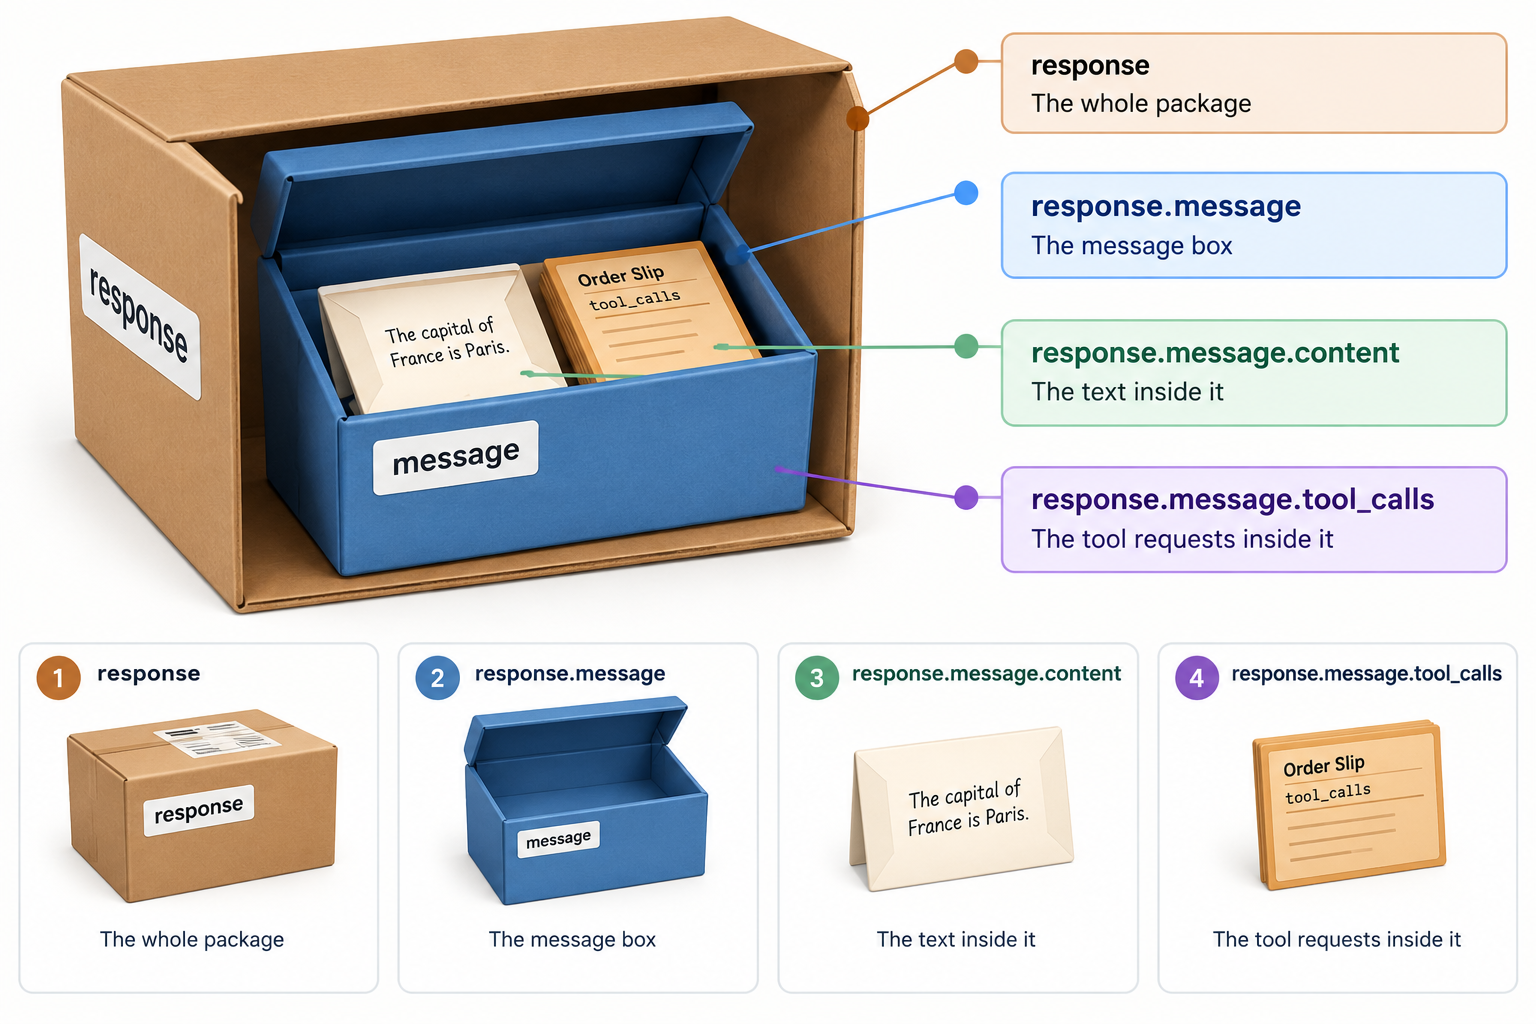

3. The two kinds of reply

The model’s message is one of two kinds:
```
Kind	content	tool_calls	Meaning
Answer	Has text	None	The model is done
Request	Empty ''	A list with items	The model wants a tool run
```
So after every call, our code asks: is tool_calls empty or not?

4. What is inside tool_calls

Your output showed:
```
[ToolCall(function=Function(name='line_total', arguments={'quantity': 4, 'unit_price': 12.5}))]
```

Read it from the outside in:
```
tool_calls                           a LIST (the square brackets [ ])
└── ToolCall                         ONE request (item 0 in the list)
    └── function                     the function being asked for
        ├── name                     "line_total"
        └── arguments                {"quantity": 4, "unit_price": 12.5}

```

```
Part	              Type	        Meaning
tool_calls	          List	        All requests from this reply. There can be several.
One item (ToolCall)	  Object	    One request
function.name	      Text	        Which function to run
function.arguments	  Dictionary	The inputs, as label and value pairs
```

In [18]:
call1 = response.message.tool_calls
print(call1)
print(call1[0])
print(call1[1])

[ToolCall(function=Function(name='line_total', arguments={'quantity': 4, 'unit_price': 12.5}))]
function=Function(name='line_total', arguments={'quantity': 4, 'unit_price': 12.5})


IndexError: list index out of range

5. Cells 20 to 22, line by line
Cell 20

```py
call = response.message.tool_calls[0]
print(call.function.name)
print(call.function.arguments)
```

```call = ...[0]```: ```tool_calls``` is a list, and ```[0]``` takes its first item. We store it in a variable called ```call```. Why a new variable? Only to avoid typing that long path again. Without it you would write response.message.```tool_calls[0]```.function.name every time. call is just a short name for one request. Any name works.

```call.function.name```: opens ```function```, then ```name```. It prints ```line_total```.

```call.function.arguments: prints the dictionary {'quantity': 4, 'unit_price': 12.5}.````

Cell 21

```py
args = call.function.arguments
result = line_total(args["unit_price"], args["quantity"])

```

```args``` is another short name, this time for the dictionary of inputs. A dictionary holds labelled values, and you read one by its label:
```
You write	You get
args["unit_price"]	12.5
args["quantity"]	4
```
Then ```line_total(12.5, 4)``` is our own function running. ```result``` becomes``` 50.0```.

This is the step the model could never do. We took its inputs and ran real code.

Cell 22

```python
messages = [
    {"role": "user", "content": "What is the total ..."},
    response.message,
    {"role": "tool", "tool_name": call.function.name, "content": str(result)},
]
final = ollama.chat(model="gemma4:e2b", messages=messages, ...)
```
We build a history of three messages and send it back:
```
#	Message	Meaning
1	Your question	What the user asked
2	response.message	The model’s own tool request, put back in the history
3	{"role": "tool", ...}	The result of our function. tool_name says which tool produced it. str(result) turns 50.0 into text.
```
The model now reads all three, so it knows: you asked, it asked for a tool, and the tool said 50.0. It writes the final answer. This is the same “send the whole history” idea from Stage 3, with one new role.

6. The whole story in one picture

```
Round 1:  we send   [ question ]  + tool list
          model     -> request: line_total(12.5, 4)        (tool_calls has 1 item)

          OUR CODE runs line_total(12.5, 4) -> 50.0

Round 2:  we send   [ question, request, result 50.0 ]
          model     -> answer: "The total is 50.00"        (tool_calls is None)

```

Two calls to ollama.chat. The first gets a request, the second gets an answer.

## How a tool call is built

**1. What `ollama.chat` returns:** one `response` object, which is a nest of boxes.

```
response
└── message
    ├── role         "assistant"
    ├── content      text (empty if the model sent a request)
    └── tool_calls   None, or a list of requests
        └── ToolCall
            └── function
                ├── name        which tool
                └── arguments   the inputs, as a dictionary
```

| Short name | Stands for |
|---|---|
| `call` | One request: `response.message.tool_calls[0]` |
| `args` | The inputs: `call.function.arguments` |
| `result` | What our function returned |

**2. Two kinds of reply**

| Kind | `content` | `tool_calls` | Meaning |
|---|---|---|---|
| Answer | Text | `None` | The model is done |
| Request | Empty | A list | The model wants a tool run |

**3. The two rounds**

| Round | We send | The model sends back |
|---|---|---|
| 1 | Question and tool list | A request for a tool |
| (our code) | Runs the function | |
| 2 | Question, request, and result (role `tool`) | The final answer |

In [24]:
# Cell 24: A simple agent loop with a limit on the number of rounds
TOOLS = {"line_total": line_total, "lookup_price": lookup_price}

def run_agent(question, max_rounds=5):
    messages = [{"role": "user", "content": question}]

    for round_number in range(1, max_rounds + 1):
        response = ollama.chat(
            model="gemma4:e2b", messages=messages,
            tools=list(TOOLS.values()), think=False,
        )
        messages.append(response.message)           # keep the model's message

        if not response.message.tool_calls:         # no request: the model is done
            return response.message.content

        for call in response.message.tool_calls:    # run every requested tool
            name = call.function.name
            result = TOOLS[name](**call.function.arguments)
            print(f"Round {round_number}: {name}({call.function.arguments}) -> {result}")
            messages.append({"role": "tool", "tool_name": name, "content": str(result)})

    return "Stopped: reached the round limit."

print(run_agent("What is the price of 3 busbars?"))

What kind of busbars are you referring to? Could you please provide more details so I can look up the price?


###  What happened in Cell 24

Cell 24 should print a Round 1: ... line each time a tool runs. No such line appeared, so the model never asked for lookup_price. It replied with a question instead.

The loop did what it should. A reply with no tool request means “the model is finished”, so it returned that text. The stop rule worked. The problem is on the model’s side:
```
Cause	Detail
The model doesn’t know the part names	It can’t see PRICES. It only sees the docstring.
Our docstring was too thin	It said “part name in lowercase” but never listed the names.
The question was vague	“3 busbars” is not an exact part name.
```
This happens a lot with small models: a tool is only as good as its description. Three fixes follow, from simplest to strongest.

## Why the agent asked a question instead of using the tool

The loop stopped because the model sent text and no tool request. The cause was a thin tool description.

| Fix | Idea |
|---|---|
| 1. Better docstring | List the valid part names inside the docstring |
| 2. A `list_parts` tool | Let the model look up what exists before it asks for a price |
| 3. Errors that explain | When a name is wrong, return a message listing the valid names, instead of crashing |

**Rule:** the model only knows what the tool description tells it. Write the description for a reader who has never seen your code.

In [25]:
# Cell 24: A simple agent loop with a limit on the number of rounds
TOOLS = {"line_total": line_total, "lookup_price": lookup_price}

def run_agent(question, max_rounds=5):
    messages = [{"role": "user", "content": question}]

    for round_number in range(1, max_rounds + 1):
        response = ollama.chat(
            model="gemma4:e2b", messages=messages,
            tools=list(TOOLS.values()), think=False,
        )
        messages.append(response.message)

        if not response.message.tool_calls:
            return response.message.content

        for call in response.message.tool_calls:
            name = call.function.name
            result = TOOLS[name](**call.function.arguments)
            print(f"Round {round_number}: {name}({call.function.arguments}) -> {result}")
            messages.append({"role": "tool", "tool_name": name, "content": str(result)})

    return "Stopped: reached the round limit."

print(run_agent("What is the price of 3 busbars?"))

What kind of busbars are you referring to? Could you provide more details or a part number?


## Cell 24: the agent loop, explained

**The big idea:** Cell 24 is a helper with a checklist and a limit of 5 attempts.

Ask the model. If the model only talks, give that answer back and stop. If the model asks for a tool, run it, hand the result back, and ask again. Never try more than 5 times.

---

### Part 1: the tool menu

```python
TOOLS = {"line_total": line_total, "lookup_price": lookup_price}
```

This is a **dictionary**: labels on the left, values on the right.

| Label (text) | Value (the function itself) |
|---|---|
| `"line_total"` | The function `line_total` |
| `"lookup_price"` | The function `lookup_price` |

**Why we need it:** the model sends a **name as text**, such as `"lookup_price"`. Our code must turn that text into the real function. `TOOLS["lookup_price"]` does that.

**Picture:** a menu card. The model says a dish name, and the menu tells the kitchen which recipe to cook.

---

### Part 2: the function and its two inputs

```python
def run_agent(question, max_rounds=5):
```

| Input | Meaning |
|---|---|
| `question` | What the user asks |
| `max_rounds=5` | The safety limit. The `=5` is a **default**, used when no other number is given. |

---

### Part 3: the history starts with the question

```python
messages = [{"role": "user", "content": question}]
```

The list of messages we send to the model. It starts with one message: the user's question.

---

### Part 4: the loop

```python
for round_number in range(1, max_rounds + 1):
```

`range(1, 6)` gives the numbers 1, 2, 3, 4, 5. The `for` line runs the indented block below it **once for each number**, and `round_number` holds the current one.

| Pass | `round_number` |
|---|---|
| First | 1 |
| Second | 2 |
| ... up to | 5 |

After 5 passes the loop ends by itself. This is the **safety limit**. It stops the agent from running forever.

---

### Part 5: ask the model

```python
response = ollama.chat(
    model="gemma4:e2b", messages=messages,
    tools=list(TOOLS.values()), think=False,
)
```

The same call as before. One new piece: `list(TOOLS.values())` takes the functions out of the dictionary and makes a list, because `tools=` wants a list.

---

### Part 6: save the model's reply

```python
messages.append(response.message)
```

We add the model's new message to the history, so the next round can see everything that has happened.

---

### Part 7: the stop check (the most important line)

```python
if not response.message.tool_calls:
    return response.message.content
```

| `tool_calls` | What `not` does | Result |
|---|---|---|
| `None` or an empty list | `not None` is `True` | The `if` runs: **return the text and stop** |
| A list with requests | `not [...]` is `False` | The `if` is skipped: **keep going** |

`return` ends the whole function straight away. Nothing below it runs.

---

### Part 8: run the requested tools

```python
for call in response.message.tool_calls:
    name = call.function.name
    result = TOOLS[name](**call.function.arguments)
    print(f"Round {round_number}: {name}({call.function.arguments}) -> {result}")
    messages.append({"role": "tool", "tool_name": name, "content": str(result)})
```

This only runs when the model **asked** for a tool.

| Line | Meaning |
|---|---|
| `for call in ...` | Go through each request, one at a time |
| `name = call.function.name` | Which tool, as text, such as `"lookup_price"` |
| `TOOLS[name]` | Turn that text into the real function |
| `(**call.function.arguments)` | Run it with the model's inputs. `**` unpacks `{"part_name": "busbar"}` into `part_name="busbar"`. |
| `print(f"Round ...")` | A log line, so we can see what ran |
| `messages.append({"role": "tool", ...})` | Add the result to the history |

After this, the loop goes back to Part 5 for the next round.

---

### Part 9: the last line

```python
return "Stopped: reached the round limit."
```

If all 5 rounds passed and the model **still** wanted tools, we give up with this message.

---

### Summary table

| Part | Code | Meaning |
|---|---|---|
| 1 | `TOOLS = {...}` | Turns a tool **name** (text) into the real function |
| 2 | `def run_agent(question, max_rounds=5)` | The helper, with a safety limit |
| 3 | `messages = [...]` | The history, starting with the question |
| 4 | `for round_number in range(1, max_rounds + 1)` | Repeat at most 5 times |
| 5 | `ollama.chat(...)` | Ask the model |
| 6 | `messages.append(response.message)` | Save its reply to the history |
| 7 | `if not tool_calls: return ...` | **Stop rule:** no request means done |
| 8 | `for call in tool_calls: ...` | Run each requested tool, save the result |
| 9 | `return "Stopped: ..."` | The model never finished within the limit |

**Two ways the loop ends**

| Ending | Cause |
|---|---|
| Normal | The model replies with text and no tool request |
| Safety | The round limit is reached |

---

### What happened in my run

The output was: *"What kind of busbars are you referring to?..."*

| Step | What happened |
|---|---|
| 1 | `messages` held one message: "What is the price of 3 busbars?" |
| 2 | **Round 1.** We asked the model. |
| 3 | The model replied with a **question** (text only). It sent no tool request. |
| 4 | We saved that reply to the history. |
| 5 | **Part 7:** `tool_calls` was empty, so `not` made it true, and the function **returned the text and ended**. |
| 6 | Parts 8 and 9 never ran, so no `Round 1:` line printed. |

**The loop worked.** It stopped because the model stopped asking for tools. The model simply chose to ask a question instead of using a tool.

---

### Check questions

1. In Part 7, what makes the function stop and give back an answer?
2. Why do we need the `TOOLS` dictionary?
3. In my run, why did no `Round 1: ...` line print?

In [26]:
# Cell 25: A lookup tool with a full description and a helpful error message

def lookup_price(part_name: str) -> float:
    """Return the unit price of one part.
    Valid part names: circuit breaker, busbar, cable gland.
    Use the exact name in lowercase."""
    name = part_name.strip().lower()
    if name in PRICES:
        return str(PRICES[name])
    return f"Unknown part name: '{part_name}'. Valid names are: {', '.join(PRICES.keys())}."

print(lookup_price("busbar"))  # Should return 80.0
print(lookup_price("fuse"))    # Should return an error message

80.0
Unknown part name: 'fuse'. Valid names are: circuit breaker, busbar, cable gland.


## Cell 25: a tool the model can use

**The big idea:** the same tool, made better in three ways.

| Change | Why |
|---|---|
| The docstring lists the valid part names | The model asked "which busbars?" in Cell 24 because it didn't know the names |
| The name is cleaned before the lookup | "Busbar " and "busbar" should both work |
| A wrong name returns a helpful message | Before, a wrong name crashed with a `KeyError` |

| Part | Code | Meaning |
|---|---|---|
| 1 | `def lookup_price(part_name: str) -> str:` | Replaces the old function. Now returns text. |
| 2 | The docstring | The model reads it. It lists the valid names. |
| 3 | `name = part_name.strip().lower()` | Remove edge spaces, then make lowercase |
| 4 | `if name in PRICES:` | Is the name a label in the dictionary? |
| 5 | `return str(PRICES[name])` | Good case: the price, as text |
| 6 | `return f"Unknown part ..."` | Bad case: a message that lists the valid parts |

**Expected output**

```
80.0
Unknown part 'fuse'. Valid parts: circuit breaker, busbar, cable gland
```

**Rule:** the model only knows what the tool description tells it. Write the description for a reader who has never seen your code.

**Watch out:** `TOOLS` still holds the old function until we rebuild it.

In [27]:
# Cell 26: A tool that lists the valid part names
def list_parts() -> str:
    """List every part that has a price, separated by commas."""
    return ", ".join(PRICES)

print(list_parts())

circuit breaker, busbar, cable gland


## Cell 26: a tool that lists what exists

**The big idea:** a tool the model can call **before** it asks for a price, to find out which parts exist. It reads the names straight from `PRICES`, so it never goes out of date.

**Picture:** asking the waiter for the menu before you order.

| Part | Code | Meaning |
|---|---|---|
| 1 | `def list_parts() -> str:` | A function with **no inputs**, giving back text |
| 2 | The docstring | Tells the model what the tool does |
| 3 | `return ", ".join(PRICES)` | Joins the dictionary's labels into one line |

**Expected output**

```
circuit breaker, busbar, cable gland
```

**Why two ways to know the names?**

| Where | Strength |
|---|---|
| Names written in the docstring (Cell 25) | The model sees them straight away |
| `list_parts` tool (Cell 26) | Always matches `PRICES`, even after it changes |

**Open question:** does the Ollama client accept a tool with no inputs? We test it in Cell 27.

In [28]:
# Cell 27: Offer all three tools and run the agent
TOOLS = {
    "line_total": line_total,
    "lookup_price": lookup_price,
    "list_parts": list_parts,
}

print(run_agent("What is the price of one busbar?"))

Round 1: lookup_price({'part_name': 'busbar'}) -> 80.0
The price of one busbar is 80.0.


**My result:**

```
Round 1: lookup_price({'part_name': 'busbar'}) -> 80.0
The price of one busbar is 80.0.
```

| What happened | Meaning |
|---|---|
| Guess A | The model asked for `lookup_price` straight away |
| Compared with Cell 24 | Same question, but now the docstring lists the valid part names, so the model used the tool |

**Lesson:** a better tool description changed the agent's behaviour, with no change to the loop.

In [29]:
# Cell 28: A question that needs two tools in a row
print(run_agent("How much do 3 busbars cost in total?"))

Round 1: lookup_price({'part_name': 'busbar'}) -> 80.0
Round 2: line_total({'quantity': 3, 'unit_price': 80}) -> 240
The total cost for 3 busbars is 240.0.


```
Round 1:  we send the question
          model asks   lookup_price(busbar)
          our code runs it  ->  "80.0"       (added to the history)

Round 2:  we send question + request + result
          model asks   line_total(unit_price=80.0, quantity=3)
          our code runs it  ->  240.0        (added to the history)

Round 3:  we send everything so far
          model replies with TEXT, no request
          the loop stops and returns it

```

## Cell 28: two tools in a row

**The big idea:** the output of one tool becomes the input of the next. A single call can't do this. The loop can.

| Step | Tool | Why |
|---|---|---|
| 1 | `lookup_price` | Find the price of one busbar |
| 2 | `line_total` | Multiply that price by 3 |

```
Round 1:  model asks lookup_price(busbar)          our code -> "80.0"
Round 2:  model asks line_total(80.0, 3)           our code -> 240.0
Round 3:  model replies with text, loop stops
```

**How to check an answer:** every number in the final answer must have a `Round` line behind it. A number with no matching `Round` line came from the model's own guess.

| Result | Meaning |
|---|---|
| Two `Round` lines, then the answer | The model chained the tools correctly |
| One `Round` line, answer is the product | The model did the multiplication itself |
| No `Round` line, answer has a price | The model made up the price |


**My result:**

```
Round 1: lookup_price({'part_name': 'busbar'}) -> 80.0
Round 2: line_total({'quantity': 3, 'unit_price': 80}) -> 240
The total cost for 3 busbars is 240.0.
```

| What happened | Meaning |
|---|---|
| Guess A | The model chained the two tools correctly |
| Round 2 input | `unit_price: 80` came from the Round 1 result |
| Final answer | Every number has a `Round` line behind it, so no number was made up |

**Surprise:** the tool result `"80.0"` was text, but the model sent a real number to `line_total`. This worked, but it is not guaranteed. A type check would guarantee it.

In [30]:
# Cell 29: Test the safety limit with only one round allowed
print(run_agent("How much do 3 busbars cost in total?", max_rounds=1))

Round 1: lookup_price({'part_name': 'busbar'}) -> 80.0
Stopped: reached the round limit.


## Cell 29: the safety limit

**The big idea:** `max_rounds` stops an agent from running forever. We give it one round for a question that needs two, and see what happens.

```python
print(run_agent("How much do 3 busbars cost in total?", max_rounds=1))
```

| Part of Cell 24 | What it does here |
|---|---|
| `for round_number in range(1, max_rounds + 1)` | With `max_rounds=1`, the loop runs once |
| Part 8 | Runs the requested tool in round 1 and saves the result |
| Part 9 | After the loop ends, returns `Stopped: reached the round limit.` |



**Why it matters:** an agent with no limit could repeat a tool forever, wasting time and money. A limit turns an endless loop into a clear message.

**My guess:** A (a round-1 tool call, then the stop message)

**My result:**

```
Round 1: lookup_price({'part_name': 'busbar'}) -> 80.0
Stopped: reached the round limit.
```

| What happened | Meaning |
|---|---|
| Round 1 ran | The model asked for the price and our code ran `lookup_price` |
| No `line_total` call | The second round never started |
| `Stopped: ...` | The loop ended, and Part 9 returned the safety message |

**Lesson:** the limit turns a possible endless loop into a clear message. It does not give an answer. It stops the agent safely.

## Stage 5 summary: tools and the agent loop

| Idea | What it means |
|---|---|
| Tool | A normal Python function the model may ask for |
| Tool request | The model sends a request, never runs the function |
| `tool_calls` | A list of requests inside `response.message` |
| Role `tool` | Carries our function's result back to the model |
| `TOOLS` dictionary | Turns a tool name (text) into the real function |
| Agent loop | Ask, run requested tools, send results back, repeat |
| Stop rule | No tool request means the model is finished |
| Safety limit | `max_rounds` stops the loop from running forever |

| Cell | What we learned |
|---|---|
| 18 | A model with a tool available still answers normally when it needs no tool |
| 19 | A question that needs a tool gets a request, with empty `content` |
| 21 and 22 | Our code runs the function. The model writes the final answer. |
| 24 | The loop, in nine parts |
| 25 | A good docstring changes the agent's behaviour |
| 26 | A tool with no inputs that lists what exists |
| 27 | The agent used `lookup_price` once the names were in the docstring |
| 28 | Two tools in a row: the first result became the second input |
| 29 | The round limit stopped the loop safely |

**Rules to keep**

1. The model only knows what the tool description tells it.
2. Every number in a final answer must have a `Round` line behind it.
3. A tool should return a clear message on bad input, not crash.
4. Always set a round limit.

## Review: what I have built so far

**Goal:** a small assistant that prices electrical parts and shows how it decided, built with Gemma 4 on Colab. All data is invented.

| Stage | What I learned | Evidence in my files |
|---|---|---|
| 0. Setup | Colab with a T4 GPU, Ollama, Gemma 4 (small size). The session resets, so setup runs each time. | Setup cells 1 to 6 |
| 1. Messages | One `ollama.chat` call. The message text controls the answer. | Tutorial 01 |
| 2. Roles and history | The model has no memory. `system`, `user`, `assistant`, `tool` are the roles. | Memory tests |
| 3. The `ask` helper | A list that grows with every turn is the only memory. | `chat_history` |
| 4. Structured output | `format="json"` gives valid JSON but not the right keys. Pydantic checks the shape. | `Part` form |
| 5. Tools and the agent loop | The model sends a request. Our code runs the function. The loop repeats until no request is left. | Cells 17 to 29 |
| Project, `tools.py` | Three tested tools: `lookup_price`, `list_parts`, `line_total` | `project/src/tools.py` |
| Project, `agent.py` | `run_tool`: runs a tool by name and never crashes | `project/src/agent.py` |

**Rules I keep**

1. The model only knows what the tool description tells it.
2. Every number in a final answer needs a `Round` line behind it.
3. A tool returns a clear message on bad input. It never crashes.
4. An agent always has a round limit.
5. Valid JSON is not the same as correct JSON.
6. A small model's facts must be checked.
7. Invented data only. No real company data, no copied text.